## 01_icu_classifier_dataset_analysis.ipynb



## Section 0 – Setup

In [ ]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 120)

def resolve_root() -> Path:
    cwd = Path.cwd().resolve()
    if (cwd / 'data').exists() and (cwd / 'notebooks').exists():
        return cwd
    if cwd.name == 'notebooks' and (cwd.parent / 'data').exists():
        return cwd.parent
    return cwd

ROOT = resolve_root()
DATA_PROCESSED  = ROOT / 'data' / 'processed'
DATA_ANALYSIS   = ROOT / 'data' / 'analysis'

DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
DATA_ANALYSIS.mkdir(parents=True, exist_ok=True)

OFFICIAL_DATASET = DATA_PROCESSED / 'dataset_master.csv'

EXPECTED_LABELS = [
    'information_generale',
    'sensible_reformulable',
    'avis_medical_personnalise',
    'urgence',
    'hors_perimetre',
]

print('ROOT =', ROOT)
print('OFFICIAL_DATASET =', OFFICIAL_DATASET)


ROOT = C:\Users\223114186\Documents\chatbot_ia\icu_chatbot
OFFICIAL_DATASET = C:\Users\223114186\Documents\chatbot_ia\icu_chatbot\data\processed\dataset_master.csv


## Section 1 – Dataset loading

In [14]:
if not OFFICIAL_DATASET.exists():
    raise FileNotFoundError(
        f'Official dataset not found: {OFFICIAL_DATASET}\n'
        f'Expected path: data/processed/dataset_master.csv'
    )

df = pd.read_csv(OFFICIAL_DATASET)

REQUIRED_COLUMNS = ['text', 'label', 'topic', 'source']
missing_cols = [c for c in REQUIRED_COLUMNS if c not in df.columns]
if missing_cols:
    raise ValueError(
        f'Required columns missing from dataset_master.csv: {missing_cols}\n'
        f'Found columns: {list(df.columns)}'
    )

df = df[REQUIRED_COLUMNS].copy()
df['text'] = df['text'].astype(str).str.strip()

print('Dataset loaded successfully.')
print(f'File: {OFFICIAL_DATASET}')
print(f'Rows: {len(df):,}')
print(f'Columns: {list(df.columns)}')

Dataset loaded successfully.
File: C:\Users\223114186\Documents\chatbot_ia\icu_chatbot\data\processed\dataset_master.csv
Rows: 16,136
Columns: ['text', 'label', 'topic', 'source']


## Section 2 – Dataset overview

In [15]:
print('='*60)
print('DATASET OVERVIEW')
print('='*60)
print(f'Total rows    : {len(df):,}')
print(f'Total columns : {len(df.columns)}')
print(f'Columns       : {list(df.columns)}')
print()

print('--- First 10 rows ---')
display(df.head(10))

print('--- Missing values ---')
missing = df.isnull().sum().rename('missing').to_frame()
missing['pct'] = (missing['missing'] / len(df) * 100).round(2)
display(missing)

dup_count = int(df['text'].duplicated().sum())
print(f'Duplicate text rows: {dup_count:,} ({dup_count/len(df)*100:.2f}%)')

DATASET OVERVIEW
Total rows    : 16,136
Total columns : 4
Columns       : ['text', 'label', 'topic', 'source']

--- First 10 rows ---


,text,label,topic,source
0,What is (are) Parasites - Trichuriasis (also known as Whipworm Infection) ?,information_generale,infection,medquad
1,Who is at risk for Parasites - Trichuriasis (also known as Whipworm Infection)? ?,information_generale,infection,medquad
2,How to diagnose Parasites - Trichuriasis (also known as Whipworm Infection) ?,avis_medical_personnalise,infection,medquad
3,What are the treatments for Parasites - Trichuriasis (also known as Whipworm Infection) ?,avis_medical_personnalise,infection,medquad
4,How to prevent Parasites - Trichuriasis (also known as Whipworm Infection) ?,information_generale,infection,medquad
5,What is (are) Parasites - Toxocariasis (also known as Roundworm Infection) ?,information_generale,infection,medquad
6,Who is at risk for Parasites - Toxocariasis (also known as Roundworm Infection)? ?,information_generale,infection,medquad
7,How to diagnose Parasites - Toxocariasis (also known as Roundworm Infection) ?,avis_medical_personnalise,infection,medquad
8,What are the treatments for Parasites - Toxocariasis (also known as Roundworm Infection) ?,avis_medical_personnalise,infection,medquad
9,How to prevent Parasites - Toxocariasis (also known as Roundworm Infection) ?,information_generale,infection,medquad


--- Missing values ---


,missing,pct
text,0,0.0
label,0,0.0
topic,0,0.0
source,0,0.0


Duplicate text rows: 0 (0.00%)


## Section 3 – Label analysis

--- Rows per label ---


,label,rows,pct
0,sensible_reformulable,5762,35.71
1,avis_medical_personnalise,4788,29.67
2,information_generale,3212,19.91
3,urgence,2023,12.54
4,hors_perimetre,351,2.18


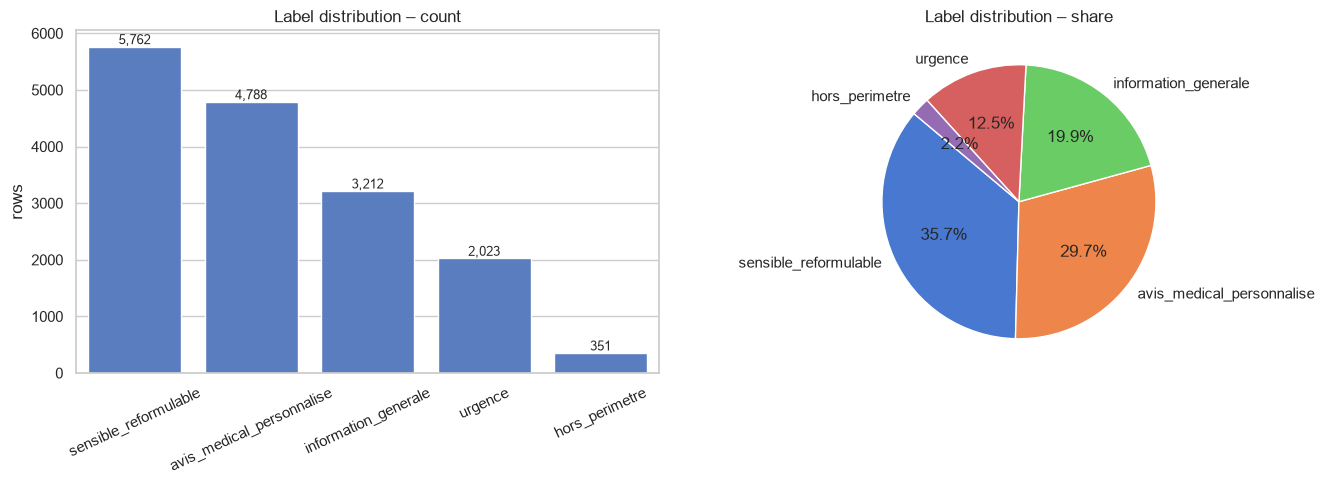

In [16]:
label_counts = (
    df['label']
    .value_counts()
    .rename_axis('label')
    .reset_index(name='rows')
)
label_counts['pct'] = (label_counts['rows'] / len(df) * 100).round(2)

print('--- Rows per label ---')
display(label_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=label_counts, x='label', y='rows', ax=axes[0])
axes[0].set_title('Label distribution – count')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=25)
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha='center', va='bottom', fontsize=9)

axes[1].pie(
    label_counts['rows'],
    labels=label_counts['label'],
    autopct='%1.1f%%',
    startangle=140,
    wedgeprops={'edgecolor': 'white'}
)
axes[1].set_title('Label distribution – share')

plt.tight_layout()
plt.show()

## Section 4 – Topic analysis

--- Rows per topic ---


,topic,rows,pct
0,medication,3922,24.31
1,imaging,2526,15.65
2,lab_results,2334,14.46
3,infection,2207,13.68
4,oxygen_saturation,1085,6.72
5,monitoring,668,4.14
6,dialysis,568,3.52
7,communication_with_team,455,2.82
8,surgery,423,2.62
9,end_of_life,335,2.08


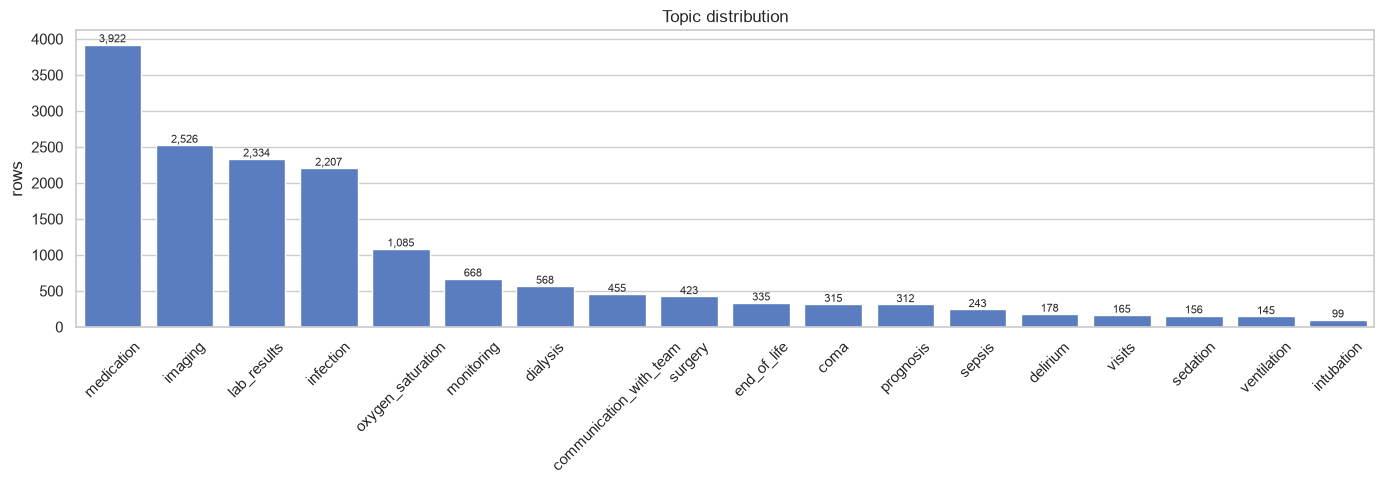

In [17]:
topic_counts = (
    df['topic']
    .value_counts()
    .rename_axis('topic')
    .reset_index(name='rows')
)
topic_counts['pct'] = (topic_counts['rows'] / len(df) * 100).round(2)

print('--- Rows per topic ---')
display(topic_counts)

plt.figure(figsize=(14, 5))
ax = sns.barplot(data=topic_counts, x='topic', y='rows')
ax.set_title('Topic distribution')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=45)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.show()

## Section 5 – Source analysis

--- Rows per source ---


,source,rows,pct
0,mediqal,8015,49.67
1,parhaf,3676,22.78
2,chatdoctor,3471,21.51
3,frenchmedmcqa,557,3.45
4,medquad,417,2.58


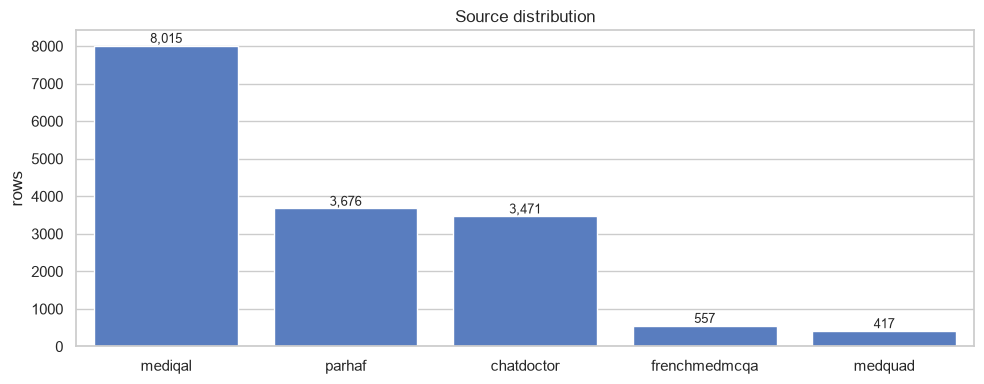

In [18]:
source_counts = (
    df['source']
    .value_counts()
    .rename_axis('source')
    .reset_index(name='rows')
)
source_counts['pct'] = (source_counts['rows'] / len(df) * 100).round(2)

print('--- Rows per source ---')
display(source_counts)

plt.figure(figsize=(10, 4))
ax = sns.barplot(data=source_counts, x='source', y='rows')
ax.set_title('Source distribution')
ax.set_xlabel('')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

## Section 6 – Cross analysis

--- Label × Topic ---


topic,coma,communication_with_team,delirium,dialysis,end_of_life,imaging,infection,intubation,lab_results,medication,monitoring,oxygen_saturation,prognosis,sedation,sepsis,surgery,ventilation,visits
label,,,,,,,,,,,,,,,,,,
avis_medical_personnalise,26,16,3,231,146,975,152,23,751,1942,76,28,198,56,67,87,8,3
hors_perimetre,0,7,1,5,6,36,36,2,105,48,16,70,4,4,5,0,6,0
information_generale,169,190,48,7,0,468,978,6,107,874,170,50,0,5,29,39,32,40
sensible_reformulable,101,200,113,303,139,889,980,41,805,906,248,406,107,54,49,255,53,113
urgence,19,42,13,22,44,158,61,27,566,152,158,531,3,37,93,42,46,9


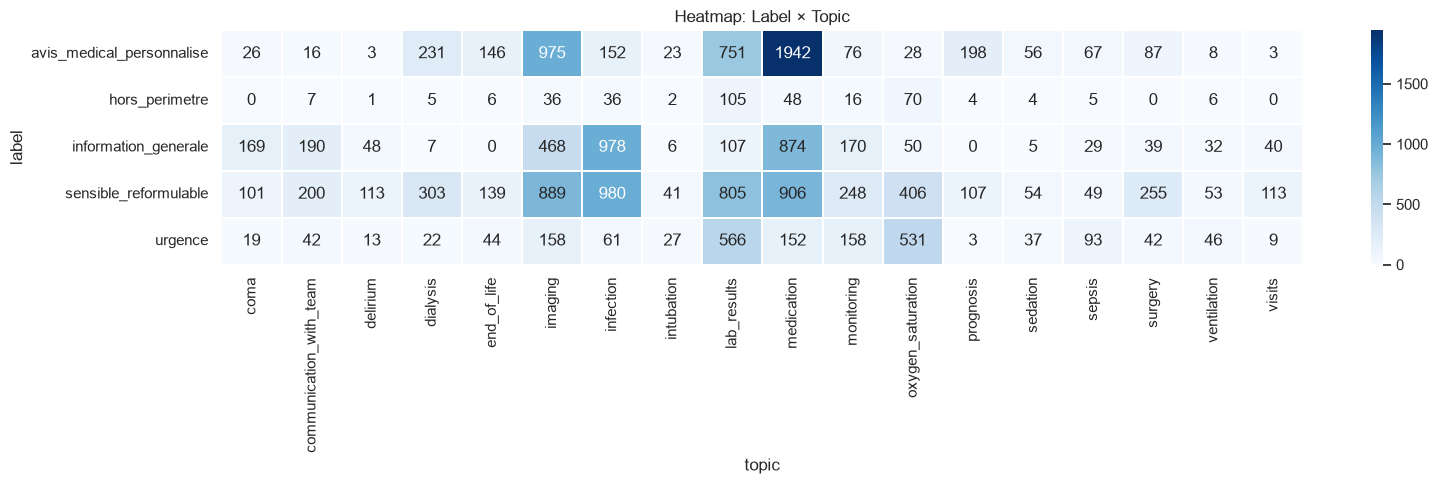

--- Label × Source ---


source,chatdoctor,frenchmedmcqa,mediqal,medquad,parhaf
label,,,,,
avis_medical_personnalise,1573,121,2825,160,109
hors_perimetre,0,4,87,0,260
information_generale,1,133,2810,220,48
sensible_reformulable,1798,299,2085,37,1543
urgence,99,0,208,0,1716


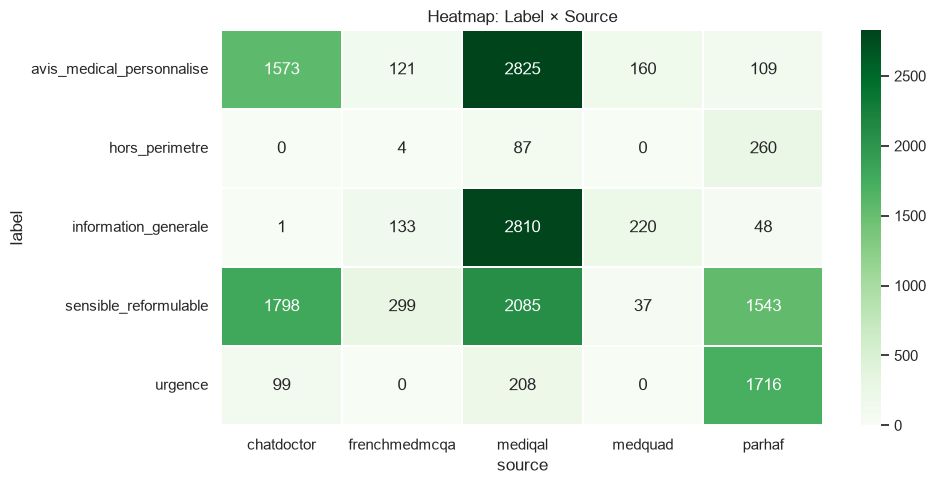

--- Topic × Source ---


source,chatdoctor,frenchmedmcqa,mediqal,medquad,parhaf
topic,,,,,
coma,59,6,127,112,11
communication_with_team,66,0,312,3,74
delirium,86,0,80,1,11
dialysis,515,1,11,7,34
end_of_life,242,0,6,2,85
imaging,365,195,1516,14,436
infection,549,170,1176,178,134
intubation,44,0,11,0,44
lab_results,180,13,900,40,1201


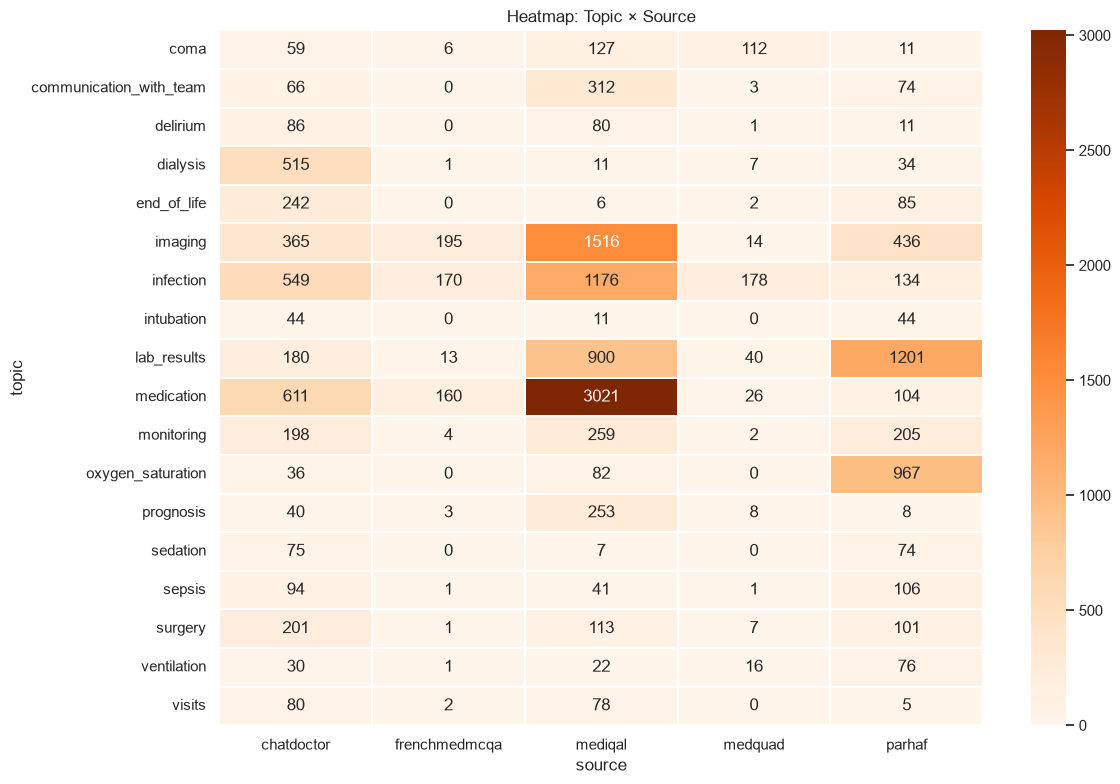

In [19]:
print('--- Label × Topic ---')
cross_lt = pd.crosstab(df['label'], df['topic'])
display(cross_lt)

plt.figure(figsize=(16, 5))
sns.heatmap(cross_lt, annot=True, fmt='d', cmap='Blues', linewidths=0.3)
plt.title('Heatmap: Label × Topic')
plt.tight_layout()
plt.show()

print('--- Label × Source ---')
cross_ls = pd.crosstab(df['label'], df['source'])
display(cross_ls)

plt.figure(figsize=(10, 5))
sns.heatmap(cross_ls, annot=True, fmt='d', cmap='Greens', linewidths=0.3)
plt.title('Heatmap: Label × Source')
plt.tight_layout()
plt.show()

print('--- Topic × Source ---')
cross_ts = pd.crosstab(df['topic'], df['source'])
display(cross_ts)

plt.figure(figsize=(12, 8))
sns.heatmap(cross_ts, annot=True, fmt='d', cmap='Oranges', linewidths=0.3)
plt.title('Heatmap: Topic × Source')
plt.tight_layout()
plt.show()

## Section 7 – Text quality analysis

--- Text length statistics ---


,char_len,word_len
count,16136.0,16136.0
mean,661.6,101.7
std,840.6,124.0
min,15.0,3.0
25%,106.0,15.0
50%,252.0,39.0
75%,797.0,146.0
max,3000.0,512.0



--- 20 shortest texts (by characters) ---


,text,label,topic,source,char_len
5387,Le traitement :,information_generale,medication,mediqal,15
8892,Les herpès virus,information_generale,infection,frenchmedmcqa,16
4790,La mucoviscidose :,avis_medical_personnalise,medication,mediqal,18
7096,Commenter le bilan,avis_medical_personnalise,lab_results,mediqal,18
5371,L'infection à VIH :,information_generale,infection,mediqal,19
74,What is (are) Coma ?,information_generale,coma,medquad,20
696,Le traitement sera :,information_generale,medication,mediqal,20
5156,Le delirium tremens :,information_generale,delirium,mediqal,21
170,What causes Glaucoma ?,information_generale,coma,medquad,22
244,What is (are) Sepsis ?,information_generale,sepsis,medquad,22



--- 20 longest texts (by characters) ---


,text,label,topic,source,char_len
9188,"Compte rendu d'hospitalisation du service de Cancérologie\n\nConcerne Madame Monique GALLOIS, née le 28/10/64.\n\nCo...",hors_perimetre,imaging,parhaf,3000
9236,"Compte rendu d'hospitalisation du service de Cancérologie\n\nCher confrère, votre patient monsieur Mehdi Laurens a é...",sensible_reformulable,end_of_life,parhaf,3000
9302,"Compte rendu d'hospitalisation du service de Cancérologie\n\nMonsieur Marc Bezza, 61 ans, est venu en consultation d...",hors_perimetre,imaging,parhaf,3000
9309,"Compte rendu d'hospitalisation du service de Cancérologie\n\nMonsieur Abdelnasser Wermuth, 50 ans, est hospitalisé e...",urgence,lab_results,parhaf,3000
9311,"Compte rendu de consultation du service de Cancérologie\n\nJe vois ce jour, le 19 mai 2025, Madame Angele Gachet, 64...",sensible_reformulable,imaging,parhaf,3000
9313,"Compte rendu d'hospitalisation du service de Cancérologie\n\nMonsieur Gaston Cucetto, 69 ans, est hospitalisé en hôp...",hors_perimetre,imaging,parhaf,3000
9343,Compte rendu d'hospitalisation du service de Cancérologie\n\nVous trouverez ci-après le compte-rendu de consultation...,sensible_reformulable,medication,parhaf,3000
9375,Compte rendu d'hospitalisation du service de Cancérologie\n\nJe vois le 07/07/2025 en consultation de fin de radioth...,hors_perimetre,imaging,parhaf,3000
9378,"Compte rendu d'hospitalisation du service de Cancérologie\n\nChère consoeur, votre patiente madame Andree Marescaux,...",sensible_reformulable,imaging,parhaf,3000
9384,"Compte rendu d'hospitalisation du service de Cancérologie\n\nCher confère votre patient monsieur David Cougnoux, 65 ...",sensible_reformulable,imaging,parhaf,3000


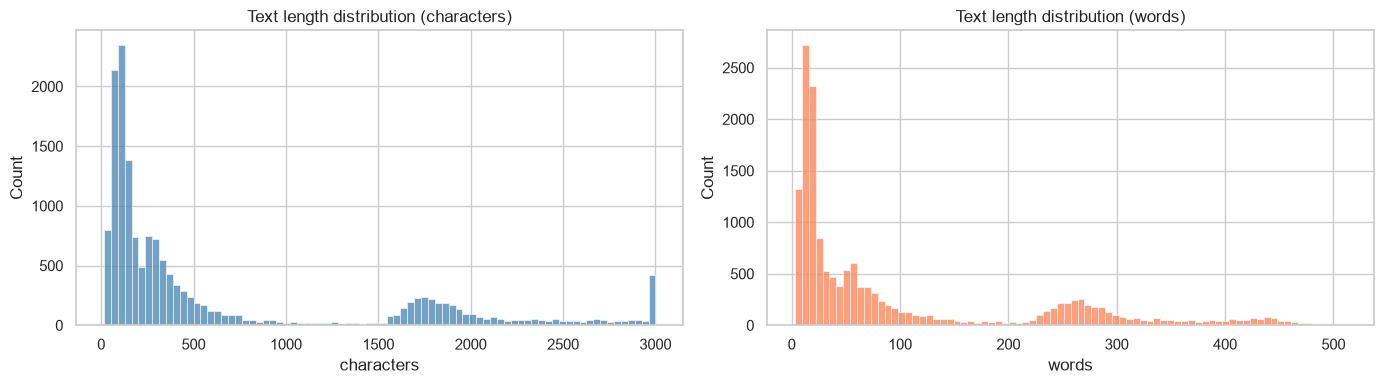


Duplicate text rows: 0


In [20]:
df['char_len'] = df['text'].str.len()
df['word_len'] = df['text'].str.split().str.len()

stats = df[['char_len', 'word_len']].describe().round(1)
print('--- Text length statistics ---')
display(stats)

print('\n--- 20 shortest texts (by characters) ---')
display(df.nsmallest(20, 'char_len')[['text', 'label', 'topic', 'source', 'char_len']])

print('\n--- 20 longest texts (by characters) ---')
display(df.nlargest(20, 'char_len')[['text', 'label', 'topic', 'source', 'char_len']])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['char_len'], bins=80, ax=axes[0], color='steelblue')
axes[0].set_title('Text length distribution (characters)')
axes[0].set_xlabel('characters')

sns.histplot(df['word_len'], bins=80, ax=axes[1], color='coral')
axes[1].set_title('Text length distribution (words)')
axes[1].set_xlabel('words')

plt.tight_layout()
plt.show()

dup_texts = df[df['text'].duplicated(keep=False)].sort_values('text')
print(f'\nDuplicate text rows: {len(dup_texts):,}')
if len(dup_texts) > 0:
    print('Sample duplicate texts:')
    display(dup_texts.head(10)[['text', 'label', 'topic', 'source']])

df.drop(columns=['char_len', 'word_len'], inplace=True)

## Section 8 – Training readiness check

In [21]:
from sklearn.model_selection import train_test_split

print('='*60)
print('TRAINING READINESS CHECK')
print('='*60)

failures = []

# 1. Minimum total rows
if len(df) < 3000:
    failures.append(f'Total rows {len(df):,} < 3,000 minimum.')
else:
    print(f'[OK] Total rows: {len(df):,}')

# 2. No missing values
for col in ['text', 'label', 'topic', 'source']:
    n_missing = int(df[col].isnull().sum())
    if n_missing > 0:
        failures.append(f'Column "{col}" has {n_missing:,} missing values.')
    else:
        print(f'[OK] No missing values in "{col}"')

# 3. All expected labels present
found_labels = set(df['label'].unique())
missing_labels = [l for l in EXPECTED_LABELS if l not in found_labels]
if missing_labels:
    failures.append(f'Missing expected labels: {missing_labels}')
else:
    print(f'[OK] All expected labels present: {EXPECTED_LABELS}')

# 4. Minimum rows per label
label_vc = df['label'].value_counts()
for label in EXPECTED_LABELS:
    count = int(label_vc.get(label, 0))
    if count < 300:
        failures.append(f'Label "{label}" has only {count} rows (minimum: 300).')
    else:
        print(f'[OK] Label "{label}": {count:,} rows')

# 5. Duplicate text count (report only, not a blocker)
dup_count = int(df['text'].duplicated().sum())
print(f'[INFO] Duplicate text count: {dup_count:,}')

print()
READY = len(failures) == 0
READY_FOR_TRAINING = 'YES' if READY else 'NO'
print(f'READY_FOR_TRAINING = {READY_FOR_TRAINING}')

if not READY:
    print('\nREASONS:')
    for i, f in enumerate(failures, 1):
        print(f'  {i}. {f}')

TRAINING READINESS CHECK
[OK] Total rows: 16,136
[OK] No missing values in "text"
[OK] No missing values in "label"
[OK] No missing values in "topic"
[OK] No missing values in "source"
[OK] All expected labels present: ['information_generale', 'sensible_reformulable', 'avis_medical_personnalise', 'urgence', 'hors_perimetre']
[OK] Label "information_generale": 3,212 rows
[OK] Label "sensible_reformulable": 5,762 rows
[OK] Label "avis_medical_personnalise": 4,788 rows
[OK] Label "urgence": 2,023 rows
[OK] Label "hors_perimetre": 351 rows
[INFO] Duplicate text count: 0

READY_FOR_TRAINING = YES


## Section 9 – Train / Val / Test split

Executed only if `READY_FOR_TRAINING = YES`.

READY_FOR_TRAINING = YES – proceeding with split.

Split sizes:
  train : 12,908 rows (80.0%)
  val   : 1,614 rows (10.0%)
  test  : 1,614 rows (10.0%)

Overlap check:
  train ∩ val  : 0
  train ∩ test : 0
  val ∩ test   : 0
  overlap_ok = True

All labels in train : True 
All labels in val   : True 
All labels in test  : True 

Saved: C:\Users\223114186\Documents\chatbot_ia\icu_chatbot\data\processed\train.csv
Saved: C:\Users\223114186\Documents\chatbot_ia\icu_chatbot\data\processed\val.csv
Saved: C:\Users\223114186\Documents\chatbot_ia\icu_chatbot\data\processed\test.csv

--- Label distribution by split ---


,split,label,rows,pct
0,train,sensible_reformulable,4609,35.7
1,train,avis_medical_personnalise,3830,29.7
2,train,information_generale,2570,19.9
3,train,urgence,1618,12.5
4,train,hors_perimetre,281,2.2
5,val,sensible_reformulable,577,35.7
6,val,avis_medical_personnalise,479,29.7
7,val,information_generale,321,19.9
8,val,urgence,202,12.5
9,val,hors_perimetre,35,2.2


--- Topic distribution by split ---


,split,topic,rows,pct
0,train,medication,3145,24.4
1,train,imaging,2038,15.8
2,train,lab_results,1810,14.0
3,train,infection,1763,13.7
4,train,oxygen_saturation,875,6.8
5,train,monitoring,544,4.2
6,train,dialysis,454,3.5
7,train,communication_with_team,374,2.9
8,train,surgery,336,2.6
9,train,end_of_life,286,2.2


--- Source distribution by split ---


,split,source,rows,pct
0,train,mediqal,6420,49.7
1,train,parhaf,2938,22.8
2,train,chatdoctor,2767,21.4
3,train,frenchmedmcqa,444,3.4
4,train,medquad,339,2.6
5,val,mediqal,797,49.4
6,val,parhaf,366,22.7
7,val,chatdoctor,357,22.1
8,val,frenchmedmcqa,56,3.5
9,val,medquad,38,2.4


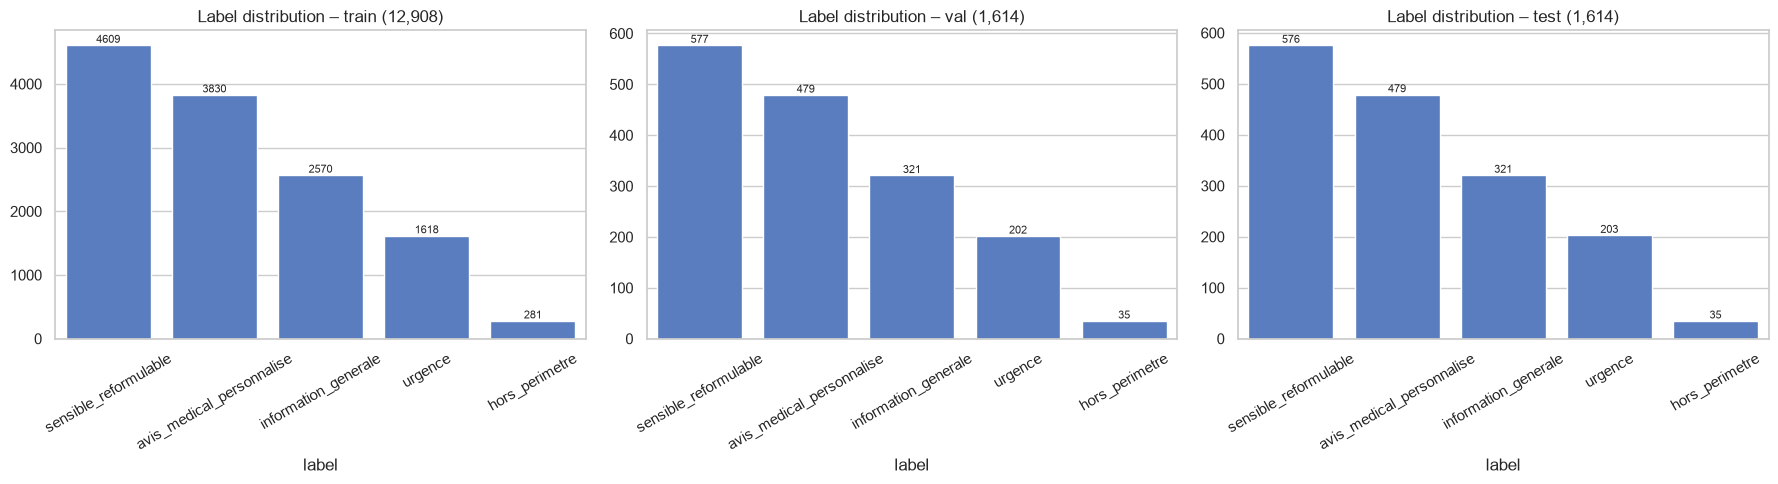

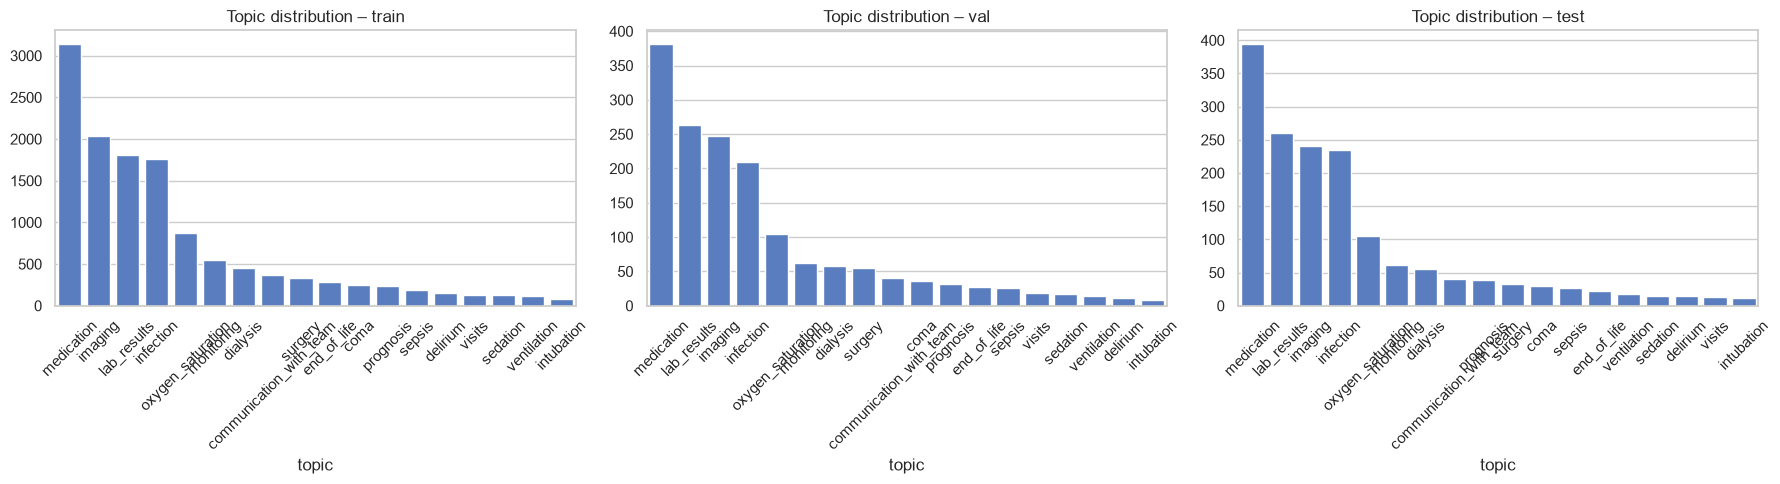

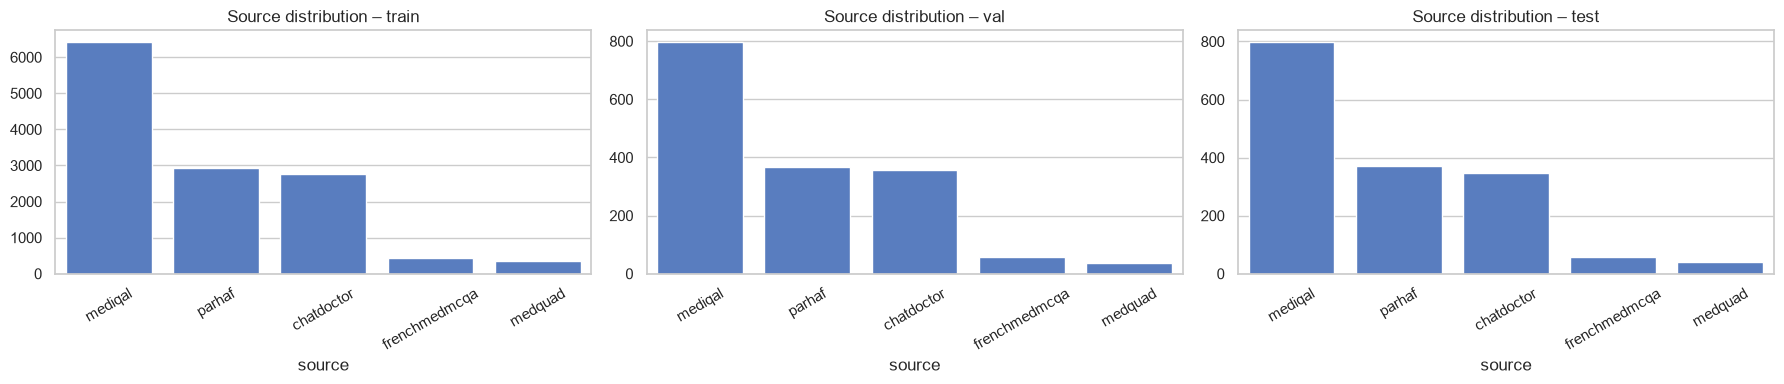

Saved: C:\Users\223114186\Documents\chatbot_ia\icu_chatbot\data\analysis\split_summary.csv


In [22]:
if not READY:
    print('READY_FOR_TRAINING = NO – split skipped.')
    print('Fix the issues listed above before proceeding.')
else:
    print('READY_FOR_TRAINING = YES – proceeding with split.')

    RANDOM_STATE = 42
    TRAIN_RATIO = 0.80
    VAL_RATIO   = 0.10
    TEST_RATIO  = 0.10

    df_clean = df.drop_duplicates(subset=['text']).reset_index(drop=True)

    # Primary split: train (80%) vs temp (20%), stratified by label
    train_df, temp_df = train_test_split(
        df_clean,
        test_size=VAL_RATIO + TEST_RATIO,
        stratify=df_clean['label'],
        random_state=RANDOM_STATE,
    )

    # Secondary split: val (50% of temp = 10% total) vs test (50% of temp = 10% total)
    val_df, test_df = train_test_split(
        temp_df,
        test_size=0.50,
        stratify=temp_df['label'],
        random_state=RANDOM_STATE,
    )

    train_df = train_df.reset_index(drop=True)
    val_df   = val_df.reset_index(drop=True)
    test_df  = test_df.reset_index(drop=True)

    print(f'\nSplit sizes:')
    print(f'  train : {len(train_df):,} rows ({len(train_df)/len(df_clean)*100:.1f}%)')
    print(f'  val   : {len(val_df):,} rows ({len(val_df)/len(df_clean)*100:.1f}%)')
    print(f'  test  : {len(test_df):,} rows ({len(test_df)/len(df_clean)*100:.1f}%)')

    # ---- overlap check ----
    train_texts = set(train_df['text'])
    val_texts   = set(val_df['text'])
    test_texts  = set(test_df['text'])

    overlap_tv = len(train_texts & val_texts)
    overlap_tt = len(train_texts & test_texts)
    overlap_vt = len(val_texts & test_texts)

    print(f'\nOverlap check:')
    print(f'  train ∩ val  : {overlap_tv}')
    print(f'  train ∩ test : {overlap_tt}')
    print(f'  val ∩ test   : {overlap_vt}')
    overlap_ok = (overlap_tv == 0) and (overlap_tt == 0) and (overlap_vt == 0)
    print(f'  overlap_ok = {overlap_ok}')

    # ---- all labels in each split ----
    missing_train = [l for l in EXPECTED_LABELS if l not in train_df['label'].unique()]
    missing_val   = [l for l in EXPECTED_LABELS if l not in val_df['label'].unique()]
    missing_test  = [l for l in EXPECTED_LABELS if l not in test_df['label'].unique()]
    print(f'\nAll labels in train : {len(missing_train) == 0} {missing_train if missing_train else ""}')
    print(f'All labels in val   : {len(missing_val) == 0} {missing_val if missing_val else ""}')
    print(f'All labels in test  : {len(missing_test) == 0} {missing_test if missing_test else ""}')

    # ---- save split files ----
    train_path = DATA_PROCESSED / 'train.csv'
    val_path   = DATA_PROCESSED / 'val.csv'
    test_path  = DATA_PROCESSED / 'test.csv'

    train_df.to_csv(train_path, index=False)
    val_df.to_csv(val_path, index=False)
    test_df.to_csv(test_path, index=False)

    print(f'\nSaved: {train_path}')
    print(f'Saved: {val_path}')
    print(f'Saved: {test_path}')

    # ---- distributions by split ----
    def dist_table(split_df, split_name, col):
        t = split_df[col].value_counts().rename_axis(col).reset_index(name='rows')
        t['pct'] = (t['rows'] / len(split_df) * 100).round(1)
        t.insert(0, 'split', split_name)
        return t

    print('\n--- Label distribution by split ---')
    label_dist = pd.concat([
        dist_table(train_df, 'train', 'label'),
        dist_table(val_df, 'val', 'label'),
        dist_table(test_df, 'test', 'label'),
    ], ignore_index=True)
    display(label_dist)

    print('--- Topic distribution by split ---')
    topic_dist = pd.concat([
        dist_table(train_df, 'train', 'topic'),
        dist_table(val_df, 'val', 'topic'),
        dist_table(test_df, 'test', 'topic'),
    ], ignore_index=True)
    display(topic_dist)

    print('--- Source distribution by split ---')
    source_dist = pd.concat([
        dist_table(train_df, 'train', 'source'),
        dist_table(val_df, 'val', 'source'),
        dist_table(test_df, 'test', 'source'),
    ], ignore_index=True)
    display(source_dist)

    # ---- charts by split ----
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)
    for ax, (split_name, split_df) in zip(axes, [('train', train_df), ('val', val_df), ('test', test_df)]):
        vc = split_df['label'].value_counts()
        sns.barplot(x=vc.index, y=vc.values, ax=ax)
        ax.set_title(f'Label distribution – {split_name} ({len(split_df):,})')
        ax.tick_params(axis='x', rotation=30)
        for p in ax.patches:
            ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2, p.get_height()),
                        ha='center', va='bottom', fontsize=8)
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)
    for ax, (split_name, split_df) in zip(axes, [('train', train_df), ('val', val_df), ('test', test_df)]):
        vc = split_df['topic'].value_counts()
        sns.barplot(x=vc.index, y=vc.values, ax=ax)
        ax.set_title(f'Topic distribution – {split_name}')
        ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=False)
    for ax, (split_name, split_df) in zip(axes, [('train', train_df), ('val', val_df), ('test', test_df)]):
        vc = split_df['source'].value_counts()
        sns.barplot(x=vc.index, y=vc.values, ax=ax)
        ax.set_title(f'Source distribution – {split_name}')
        ax.tick_params(axis='x', rotation=30)
    plt.tight_layout()
    plt.show()

    # ---- save split summary ----
    split_summary = pd.concat([label_dist, topic_dist, source_dist], ignore_index=True)
    split_summary.to_csv(DATA_ANALYSIS / 'split_summary.csv', index=False)
    print(f'Saved: {DATA_ANALYSIS / "split_summary.csv"}')

## Section 10 – Save reports and final verdict

In [ ]:
# ---- dataset_final_summary.csv ----
summary_rows = []

summary_rows.append({'category': 'dataset', 'metric': 'total_rows', 'value': str(len(df))})
summary_rows.append({'category': 'dataset', 'metric': 'duplicate_text_rows', 'value': str(int(df['text'].duplicated().sum()))})
summary_rows.append({'category': 'dataset', 'metric': 'ready_for_training', 'value': READY_FOR_TRAINING})

for lbl, cnt in df['label'].value_counts().items():
    summary_rows.append({'category': 'label', 'metric': lbl, 'value': str(cnt)})

for tpc, cnt in df['topic'].value_counts().items():
    summary_rows.append({'category': 'topic', 'metric': tpc, 'value': str(cnt)})

for src, cnt in df['source'].value_counts().items():
    summary_rows.append({'category': 'source', 'metric': src, 'value': str(cnt)})

for col in ['text', 'label', 'topic', 'source']:
    summary_rows.append({'category': 'missing', 'metric': col, 'value': str(int(df[col].isnull().sum()))})

if READY:
    summary_rows.append({'category': 'split', 'metric': 'train_rows', 'value': str(len(train_df))})
    summary_rows.append({'category': 'split', 'metric': 'val_rows',   'value': str(len(val_df))})
    summary_rows.append({'category': 'split', 'metric': 'test_rows',  'value': str(len(test_df))})
    summary_rows.append({'category': 'split', 'metric': 'overlap_train_val',  'value': str(overlap_tv)})
    summary_rows.append({'category': 'split', 'metric': 'overlap_train_test', 'value': str(overlap_tt)})
    summary_rows.append({'category': 'split', 'metric': 'overlap_val_test',   'value': str(overlap_vt)})

final_summary_df = pd.DataFrame(summary_rows)
final_summary_path = DATA_ANALYSIS / 'dataset_final_summary.csv'
final_summary_df.to_csv(final_summary_path, index=False)
print(f'Saved: {final_summary_path}')

# ---- training_readiness_report.md ----
total = len(df)

md_lines = [
    '# Training Readiness Report',
    '',
    '## Dataset',
    f'- File: `data/processed/dataset_master.csv`',
    f'- Total rows: {total:,}',
    f'- Duplicate text rows: {int(df["text"].duplicated().sum()):,}',
    '',
    '## Label distribution',
    '| label | rows | pct |',
    '|---|---|---|',
]
for lbl, cnt in df['label'].value_counts().items():
    md_lines.append(f'| {lbl} | {cnt:,} | {cnt/total*100:.1f}% |')

md_lines += [
    '',
    '## Topic distribution',
    '| topic | rows | pct |',
    '|---|---|---|',
]
for tpc, cnt in df['topic'].value_counts().items():
    md_lines.append(f'| {tpc} | {cnt:,} | {cnt/total*100:.1f}% |')

md_lines += [
    '',
    '## Source distribution',
    '| source | rows | pct |',
    '|---|---|---|',
]
for src, cnt in df['source'].value_counts().items():
    md_lines.append(f'| {src} | {cnt:,} | {cnt/total*100:.1f}% |')

md_lines += [
    '',
    '## Missing values',
    '| column | missing |',
    '|---|---|',
]
for col in ['text', 'label', 'topic', 'source']:
    md_lines.append(f'| {col} | {int(df[col].isnull().sum())} |')

md_lines += [
    '',
    '## Readiness checks',
]
if READY:
    md_lines.append('All checks passed.')
else:
    md_lines.append('One or more checks failed:')
    for i, f in enumerate(failures, 1):
        md_lines.append(f'{i}. {f}')

if READY:
    md_lines += [
        '',
        '## Split sizes',
        f'- train : {len(train_df):,} ({len(train_df)/total*100:.1f}%)',
        f'- val   : {len(val_df):,} ({len(val_df)/total*100:.1f}%)',
        f'- test  : {len(test_df):,} ({len(test_df)/total*100:.1f}%)',
        '',
        '## Overlap check',
        f'- train ∩ val  : {overlap_tv}',
        f'- train ∩ test : {overlap_tt}',
        f'- val ∩ test   : {overlap_vt}',
        f'- overlap_ok = {overlap_ok}',
    ]

md_lines += [
    '',
    '## Final verdict',
    f'**READY_FOR_TRAINING = {READY_FOR_TRAINING}**',
]

report_path = DATA_ANALYSIS / 'training_readiness_report.md'
report_path.write_text('\n'.join(md_lines), encoding='utf-8')
print(f'Saved: {report_path}')


Saved: C:\Users\223114186\Documents\chatbot_ia\icu_chatbot\data\analysis\dataset_final_summary.csv
Saved: C:\Users\223114186\Documents\chatbot_ia\icu_chatbot\data\analysis\training_readiness_report.md


In [25]:
print('='*60)
print(f'DATASET_PHASE_CLOSED = YES')
print()
print('OFFICIAL_DATASET:')
print('  data/processed/dataset_master.csv')
print()
if READY:
    print('SPLIT_FILES:')
    print('  data/processed/train.csv')
    print('  data/processed/val.csv')
    print('  data/processed/test.csv')
else:
    print('SPLIT_FILES: not created (READY_FOR_TRAINING = NO)')
print()
print('NOTEBOOK:')
print('  notebooks/01_icu_classifier_dataset_analysis.ipynb')
print()
print('REPORT:')
print('  data/analysis/training_readiness_report.md')
print('='*60)

DATASET_PHASE_CLOSED = YES

OFFICIAL_DATASET:
  data/processed/dataset_master.csv

SPLIT_FILES:
  data/processed/train.csv
  data/processed/val.csv
  data/processed/test.csv

NOTEBOOK:
  notebooks/01_icu_classifier_dataset_analysis.ipynb

REPORT:
  data/analysis/training_readiness_report.md
